<div style="background:linear-gradient(135deg,#123524 0%,#1f5a45 45%,#2B5A82 100%);color:#fff;padding:40px 36px;border-radius:16px;font-family:system-ui,-apple-system,'Segoe UI',sans-serif">
  <div style="font-size:12px;letter-spacing:.16em;opacity:.75;text-transform:uppercase">43008 Reinforcement Learning &middot; Assignment 3 &middot; Team LMF</div>
  <div style="font-size:46px;font-weight:800;line-height:1.05;margin:12px 0 6px">Experiment: REINFORCE</div>
  <div style="font-size:19px;opacity:.92">Monte-Carlo Policy Gradient on AgriFlight-RL, crop-row flight stabilisation</div>
  <div style="height:1px;background:rgba(255,255,255,.28);margin:24px 0 18px"></div>
  <div style="display:flex;flex-wrap:wrap;gap:36px">
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student</div><div style="font-size:20px;font-weight:600">Juan David Rodriguez Arciniegas</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student ID</div><div style="font-size:20px;font-weight:600">25418551</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Environment</div><div style="font-size:20px;font-weight:600">AgroDrone-v0 &middot; MuJoCo Skydio X2</div></div>
  </div>
</div>

### Contents

1. [Introduction](#intro): question, hypothesis, success criterion
2. [Setup](#setup): environment, config, seeds, shared helpers
3. [Theory](#theory): the algorithm in your own words
4. [Implementation](#implementation): the code
5. [Training](#training): run, curve, stability
6. [Evaluation](#evaluation): held-out seeds, baselines, difficulty levels
7. [Results](#results): table and plots
8. [Discussion](#discussion): what worked, what did not, limits
9. [Contribution and reproducibility](#contribution): who did what, versions, references

<div style="border-left:4px solid rgb(140,90,43);background:rgba(140,90,43,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Template status (delete this box before submitting).</b> <code>Run all</code> works today and produces the baseline numbers. Cells marked <i>Write here</i> or <code>TODO</code> are yours. Do not edit the cells labelled <i>Shared, identical in all three notebooks</i>: the comparison is only fair if they stay the same.</div>

<a id="intro"></a>

## 1. Introduction

<div style="border-left:4px solid rgb(74,122,94);background:rgba(74,122,94,0.10);padding:8px 12px;border-radius:0 8px 8px 0;margin:6px 0"><b>Draft in plain language.</b> Read it, make sure you can explain every sentence out loud, then rewrite it in your own voice.</div>

**Research question.** Can REINFORCE, the simplest policy-gradient method, learn to steer the drone along the crop row in wind, and how far up the difficulty ladder (L0 to L4) does it get compared with A2C and PPO?

**What REINFORCE is, in two sentences.** REINFORCE flies one whole episode, adds up the rewards, and then makes the commands it used more likely if the episode went well and less likely if it went badly. It learns only from complete flights and has no critic, so it is the simplest and noisiest of the three methods.

**Hypothesis** (Part B expects this). REINFORCE will learn the easy levels but be noisy. Its learning signal is the raw total score of an episode, so one lucky gust or one unlucky start can mislead it, and training curves will differ a lot between seeds. I expect it to clear L0, probably L1, and to struggle from L2 (wind) upwards.

**Success criterion (written before seeing any results).** *Draft: agree the exact thresholds with the team, so all three algorithms use the same definition of "clearing" a level.*
- A level is **cleared** on the 20 held-out seeds when the crash rate is at most 10%. At L0 the mean altitude error must also be at most 5 cm. From L1 up, the drone must finish the row in at least 80% of episodes.
- This notebook succeeds if L0 is cleared with all 3 training seeds and L1 with at least 2 of 3. Anything higher is a bonus, and failing at L2 or above is an acceptable, reportable result.

<a id="setup"></a>

## 2. Setup

**2.1 Bootstrap.** Finds the repo (or clones it), fetches the Skydio X2 model from the public MuJoCo Menagerie and installs any missing dependencies. Works on **AWS SageMaker**, **Google Colab** and a local Jupyter. Nothing to edit.

<details>
<summary><b>First time on SageMaker? Click here: GitHub token + clone the repo (one-off, about 5 minutes)</b></summary>

The repo is **private**, so SageMaker needs a GitHub *personal access token* to clone it. Each team member creates their own.

**A. Create a fine-grained token on GitHub**
1. GitHub (top-right avatar) → **Settings** → **Developer settings** → **Personal access tokens** → **Fine-grained tokens** → **Generate new token**.
2. *Token name*: `sagemaker-agroflight`. *Expiration*: 30 days (covers the project).
3. *Resource owner*: `Nelkit`. *Repository access*: **Only select repositories** → `agroflight-rl`. (If `Nelkit` is not in the list, ask Nelkit to confirm you are a collaborator; a classic token with the `repo` scope also works.)
4. *Permissions* → *Repository permissions* → **Contents: Read and write** (write lets you push your results).
5. **Generate token** and copy it (`github_pat_...`). GitHub shows it only once. Never paste it into a notebook cell or commit it.

**B. Clone the repo in SageMaker (from a Terminal, not from a notebook cell)**

In SageMaker Studio / JupyterLab: *File → New → Terminal*, then:
```bash
cd ~
git clone https://<YOUR_TOKEN>@github.com/Nelkit/agroflight-rl.git
cd agroflight-rl
git remote set-url origin https://github.com/Nelkit/agroflight-rl.git   # keep the token out of .git/config
git config user.name  "Your Name"
git config user.email "your.email@student.uts.edu.au"
git config credential.helper store                                     # asks for the token once on the next pull/push
git checkout -b <yourname>/<topic>                                       # one branch per person, e.g. nelkit/ppo-l0
```
When `git pull`/`git push` asks: *Username* = your GitHub user, *Password* = the token.

**C. Run**
1. Open `~/agroflight-rl/notebooks/<this notebook>.ipynb` and pick a **PyTorch** kernel (CPU is fine for Stage 1).
2. Run this cell. It detects the clone, so no token is needed here.
3. Get the latest code at any time with `git pull` in the Terminal. Commit `results/*.json` and your notebook on your branch; checkpoints (`*.pt`) are git-ignored and stay in your SageMaker home.

**Colab or a notebook opened outside the clone:** this cell clones the repo itself. It reads the token from the `GITHUB_TOKEN` environment variable, from Colab *Secrets* (key icon → add `GITHUB_TOKEN`), or asks for it with a hidden prompt. The token is not saved in the notebook or in `.git/config`.

Full guide: `docs/sagemaker_setup.md`.
</details>

In [1]:
import os, sys, subprocess, time, importlib, importlib.util
NOTEBOOK_T0 = time.time()

IN_COLAB = "google.colab" in sys.modules
IN_SAGEMAKER = bool(
    os.environ.get("SAGEMAKER_INTERNAL_IMAGE_URI") or os.environ.get("SM_CURRENT_HOST")
    or os.path.isdir("/opt/ml/metadata") or os.path.expanduser("~") == "/home/sagemaker-user"
)
PLATFORM = "colab" if IN_COLAB else ("sagemaker" if IN_SAGEMAKER else "local")

REPO_URL = "github.com/Nelkit/agroflight-rl.git"   # private repo: needs a GitHub token (see 2.1)
BRANCH = "main"                                    # only used if this cell has to clone the repo itself
CLONE_DIR = "/content/agroflight-rl" if IN_COLAB else os.path.expanduser("~/agroflight-rl")

def run(cmd, cwd=None):
    subprocess.run(cmd, cwd=cwd, check=True)

def find_repo_root(start):
    p = os.path.abspath(start)
    while True:
        if os.path.isfile(os.path.join(p, "pyproject.toml")):
            return p
        parent = os.path.dirname(p)
        if parent == p:
            return None
        p = parent

# 1. Repo: this notebook's own clone, an existing clone in CLONE_DIR, or clone it now.
REPO = find_repo_root(os.getcwd())
if REPO is None and os.path.isfile(os.path.join(CLONE_DIR, "pyproject.toml")):
    REPO = CLONE_DIR
if REPO is None:
    token = os.environ.get("GITHUB_TOKEN")
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        from getpass import getpass
        token = getpass("GitHub token for the private repo (hidden, not stored): ").strip()
    run(["git", "clone", "--quiet", "--branch", BRANCH, f"https://{token}@{REPO_URL}", CLONE_DIR])
    run(["git", "remote", "set-url", "origin", "https://" + REPO_URL], cwd=CLONE_DIR)  # drop the token
    del token
    REPO = CLONE_DIR
os.chdir(REPO)

# 2. Drone model: Skydio X2 from the public google-deepmind/mujoco_menagerie (sparse clone, a few MB).
DRONE_XML = os.path.join(REPO, "mujoco_menagerie", "skydio_x2", "x2.xml")
if not os.path.isfile(DRONE_XML):
    if not os.path.isdir("mujoco_menagerie"):
        run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
             "https://github.com/google-deepmind/mujoco_menagerie.git", "mujoco_menagerie"])
    run(["git", "sparse-checkout", "set", "skydio_x2"], cwd="mujoco_menagerie")
os.environ["AGRO_DRONE_XML"] = DRONE_XML

# 3. Dependencies: install the project (+ torch, matplotlib, pandas) only if something is missing.
if any(importlib.util.find_spec(m) is None for m in ("mujoco", "gymnasium", "torch", "matplotlib", "pandas")):
    run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[train]"])
    importlib.invalidate_caches()
sys.path.insert(0, os.path.join(REPO, "src"))
import mujoco, gymnasium   # also used by the reproducibility cell in Section 9

_head = subprocess.run(["git", "log", "-1", "--format=%h (%ad)", "--date=short"], cwd=REPO,
                       capture_output=True, text=True).stdout.strip()
_branch = subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"], cwd=REPO,
                         capture_output=True, text=True).stdout.strip()
print("platform:", PLATFORM)
print("repo    :", REPO, "| branch", _branch, "| commit", _head)
print("model   :", DRONE_XML)

repo : /Users/juandavid/Desktop/semester_4/reinforcement_learning/Project/agroflight-rl-main
model: /Users/juandavid/Desktop/semester_4/reinforcement_learning/Project/agroflight-rl-main/mujoco_menagerie/skydio_x2/x2.xml


**2.2 Experiment config and seeds.** Training seeds start at 0. Evaluation seeds start at 1000, so they are held out from training.

In [2]:
import random
import numpy as np
import torch

EXPERIMENT = dict(
    algorithm="REINFORCE",
    student_name="Juan David Rodriguez Arciniegas",
    student_id="25418551",
    env_id="AgroDrone-v0",
    train_seed=0,
    eval_seeds=list(range(1000, 1020)),
    level=0,   # start at L0; move up only when it works
)
BACKUP_TO_DRIVE = False   # set True in Colab to copy results and checkpoints to Google Drive (survives the runtime)

HPARAMS = dict(
    total_timesteps=200_000,   # per run; starting guess, not tuned
    learning_rate=3e-4,
    gamma=0.99,
    normalize_returns=False,   # was True in the template; it made L0 worse (see Section 5 debugging)
    ent_coef=0.0,
    hidden=(64, 64),
    init_log_std=-2.3,         # initial exploration noise sigma = exp(-2.3) = 0.1 (see Section 5 debugging)
    episodes_per_update=1,     # one gradient step per full episode (best of 1 and 4 in the L0 debugging)
)

random.seed(EXPERIMENT["train_seed"])
np.random.seed(EXPERIMENT["train_seed"])
torch.manual_seed(EXPERIMENT["train_seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


**2.3 Shared, identical in all three notebooks. Do not edit.** Results file schema (so one comparison notebook can read all three), checkpoint save and load (the viewer loads these), Drive backup, and the learning-curve plot.

In [3]:
import json, datetime, subprocess, shutil
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

RESULTS_DIR = os.path.join(REPO, "results")
CHECKPOINT_DIR = os.path.join(REPO, "checkpoints")

def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=REPO, text=True).strip()
    except Exception:
        return None

def new_results():
    return dict(
        schema=1,
        algorithm=EXPERIMENT["algorithm"],
        student=dict(name=EXPERIMENT["student_name"], id=EXPERIMENT["student_id"]),
        env_id=EXPERIMENT["env_id"],
        git_commit=git_commit(),
        created=datetime.datetime.now().isoformat(timespec="seconds"),
        hparams=HPARAMS,
        training=dict(train_seed=EXPERIMENT["train_seed"], total_timesteps=None, wall_clock_s=None,
                      best_checkpoint=None, curve=[]),   # curve: list of {"timesteps": int, "mean_return": float}
        evaluation=dict(eval_seeds=EXPERIMENT["eval_seeds"], baselines={}, levels={}),
    )

def save_results(results):
    os.makedirs(RESULTS_DIR, exist_ok=True)
    path = os.path.join(RESULTS_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}.json")
    with open(path, "w") as f:
        json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    return path

def save_checkpoint(model, obs_dim, act_dim, tag="best"):
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    torch.save(dict(algorithm=EXPERIMENT["algorithm"], student_id=EXPERIMENT["student_id"], hparams=HPARAMS,
                    obs_dim=obs_dim, act_dim=act_dim, state_dict=model.state_dict()), path)
    return path

def load_checkpoint(model, tag="best"):
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    ckpt = torch.load(path, map_location="cpu")
    model.load_state_dict(ckpt["state_dict"])
    return ckpt

def backup_to_drive(dirs):
    if not IN_COLAB:
        print("Not in Colab: nothing to back up.")
        return
    from google.colab import drive
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/agroflight"
    os.makedirs(dest, exist_ok=True)
    for d in dirs:
        if os.path.isdir(d):
            shutil.copytree(d, os.path.join(dest, os.path.basename(d)), dirs_exist_ok=True)
    print("backed up to", dest)

def plot_learning_curve(curve, window=10):
    xs = [p["timesteps"] for p in curve]
    ys = np.array([p["mean_return"] for p in curve], dtype=float)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(xs, ys, alpha=0.35, label="mean return")
    if len(ys) >= window:
        smooth = np.convolve(ys, np.ones(window) / window, mode="valid")
        ax.plot(xs[window - 1:], smooth, linewidth=2, label=f"moving average ({window})")
    ax.set_xlabel("environment steps")
    ax.set_ylabel("episode return")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

RESULTS = new_results()

**2.4 Environment check.** One reset and one random step, to confirm the model loads.

In [4]:
import gymnasium as gym
import agroflight.envs
from agroflight.envs import ENV_ID

env = gym.make(ENV_ID, level=EXPERIMENT["level"])
obs, _ = env.reset(seed=EXPERIMENT["train_seed"])
print("observation:", env.observation_space.shape, "| action:", env.action_space.shape)
obs, r, terminated, truncated, info = env.step(env.action_space.sample())
print("one random step -> reward", round(r, 3), "| crashed:", info["crashed"])
env.close()

observation: (14,) | action: (4,)
one random step -> reward 0.008 | crashed: False


<a id="theory"></a>

## 3. Theory

<div style="border-left:4px solid rgb(74,122,94);background:rgba(74,122,94,0.10);padding:8px 12px;border-radius:0 8px 8px 0;margin:6px 0"><b>Draft in plain language.</b> Read it, make sure you can explain every sentence out loud, then rewrite it in your own voice.</div>

#### 3.1 The idea in plain words

Imagine a coach who can only watch a whole run and then give one score. The player replays the run in their head: "in the runs that scored well I should do those things more often, and in the runs that scored badly, less often." That is REINFORCE. The drone flies a full episode with some randomness in its commands, we add up the rewards, and then we nudge the network so the commands that came before a good result become more likely, and the ones before a bad result become less likely.

#### 3.2 The steps

1. **Fly** one episode. At every step the network gives an *average* command, we add noise (sampling), and we remember how likely that exact command was (its log-probability).
2. **Score.** When the episode ends, compute for every step $t$ the *return* $G_t$: the discounted total reward from step $t$ to the end.
3. **Learn.** For every step, push the network's weights so that command becomes *more likely* if $G_t$ is high and *less likely* if $G_t$ is low, in proportion to $G_t$.
4. **Repeat** with the improved network.

Core objective, as a starting point to explain (not a substitute for the explanation):

$$\nabla_\theta J(\theta)=\mathbb{E}_{\tau\sim\pi_\theta}\Big[\sum_{t}\nabla_\theta\log\pi_\theta(a_t\mid s_t)\,G_t\Big],\qquad G_t=\sum_{k\ge t}\gamma^{\,k-t}r_k$$

#### 3.3 The equation, piece by piece

| Symbol | Plain meaning |
|---|---|
| $\theta$ | all the network's weights (what we are learning) |
| $\pi_\theta(a_t \mid s_t)$ | the probability the network gives to command $a_t$ when it senses $s_t$ |
| $\log \pi_\theta(a_t \mid s_t)$ | that probability on a log scale; its gradient says which way to change $\theta$ to make this command more likely |
| $G_t$ | how well things went from step $t$ onwards (the return) |
| $\nabla_\theta J$ | the direction in which the expected total score goes up |
| $\mathbb{E}$ | the average over many flights |

In words: **change the weights in the direction that makes each command more likely, weighted by how good the outcome was afterwards.** Good outcomes pull harder, and bad outcomes push the other way.

**Why the log trick?** The reward comes out of the simulator, and we cannot differentiate through the simulator. The log-derivative trick rewrites the gradient so that only the *network's own probabilities* need to be differentiated, while the environment only has to be *sampled*. That is what makes this a model-free method: we never use the simulator's equations.

#### 3.4 The return $G_t$, with a tiny example

$$G_t=r_t+\gamma\,r_{t+1}+\gamma^2 r_{t+2}+\dots$$

$\gamma$ (0.99 here) makes near rewards count more than far ones. Worked example with $\gamma=0.9$ and three rewards $[1,\,0,\,2]$:

- $G_2 = 2$
- $G_1 = 0 + 0.9\cdot 2 = 1.8$
- $G_0 = 1 + 0.9\cdot 1.8 = 2.62$

You compute it backwards, from the end of the episode: each return is the reward now plus $\gamma$ times the next return.

#### 3.5 Unbiased, but noisy

The push uses the *actual* return of one sampled episode. On average it points the right way (it is **unbiased**), but any single episode is a noisy estimate: one lucky gust makes a bad command look good, one unlucky start makes a good command look bad. That is the **high variance** Part B expects, and it is why REINFORCE needs many episodes and can look jumpy between seeds. A2C and PPO exist largely to reduce this noise.

**Cheap variance reduction (optional):** *return normalisation*, subtracting the mean of the returns and dividing by their standard deviation, so the push does not depend on the raw scale of the reward. It is a standard trick that usually helps a lot in practice. Subtracting a baseline from the returns is the same family of idea, and a *learned* baseline is what A2C's critic adds.

#### 3.6 A Gaussian policy for continuous actions

Our 4 commands are continuous, so the network cannot pick from a menu. Instead it outputs the **mean** $\mu_\theta(s)$ of each command, and there is a learnable **spread** $\sigma$ per command (stored as $\log\sigma$ so it stays positive). A command is sampled as $a=\mu_\theta(s)+\sigma\cdot\varepsilon$ with $\varepsilon\sim\mathcal N(0,1)$. That randomness is the **exploration**. The log-probability of the sampled 4-vector is the sum of the four per-command log-probabilities. At evaluation we drop the noise and use $a=\mu_\theta(s)$. The environment clips $a$ to $[-1,1]$, and we still compute the log-probability of the *unclipped* sample.

#### 3.7 Why the update waits for the end of the episode

$G_t$ needs the rewards that come *after* step $t$, so it cannot be computed until the episode is over. REINFORCE is therefore an *episodic, Monte-Carlo* method. A2C and PPO relax this by estimating the future with a critic.

#### 3.8 Pseudocode

```text
initialise policy weights θ and log-std
repeat for each episode:
    s ← env.reset()
    while not done:
        a ~ Normal(μ_θ(s), σ)            # sample a command
        store log π_θ(a | s)
        s, r, done ← env.step(a)
        store r
    compute G_t for every step (backwards)
    optionally normalise the G_t
    loss ← − Σ_t  log π_θ(a_t | s_t) · G_t
    θ ← θ − learning_rate · ∇θ loss      # one gradient step
```

<a id="implementation"></a>

## 4. Implementation

Write REINFORCE directly in PyTorch, following the subject's policy-gradient content. Keep the Gaussian policy head the same shape as the other two notebooks so the comparison stays fair.

**What the three pieces do.**
- `GaussianPolicy` is the network. It reads the 14 numbers the drone senses and outputs 4 *mean* commands. A separate learnable `log_std` (one number per command) sets how much random noise we add when we sample. The last layer is scaled down so the means start near 0, which means "hold position" for this environment.
- `compute_returns` turns the list of rewards of one episode into $G_t$ for every step, working backwards: $G_t = r_t + \gamma G_{t+1}$.
- `reinforce_update` does the learning: loss $=-\sum_t \log\pi(a_t|s_t)\,G_t$, then one optimiser step. Minimising the *negative* is the same as pushing the objective *up*.

In [5]:
import torch
import torch.nn as nn
from torch.distributions import Normal

class GaussianPolicy(nn.Module):
    """obs -> Gaussian over the 4 action dimensions (mean network + learnable log-std)."""
    def __init__(self, obs_dim, act_dim, hidden=HPARAMS["hidden"]):
        super().__init__()
        layers, last = [], obs_dim
        for h in hidden:                       # e.g. 14 -> 64 -> 64
            layers += [nn.Linear(last, h), nn.Tanh()]
            last = h
        layers.append(nn.Linear(last, act_dim))  # 64 -> 4 means, no activation
        self.mean_net = nn.Sequential(*layers)
        self.mean_net[-1].weight.data *= 0.01    # start with means close to 0 = "hold position"
        self.mean_net[-1].bias.data.zero_()
        # one learnable log-std per action dimension, shared by all states
        self.log_std = nn.Parameter(torch.full((act_dim,), float(HPARAMS["init_log_std"])))

    def forward(self, obs):
        return Normal(self.mean_net(obs), self.log_std.exp())

def compute_returns(rewards, gamma):
    """Discounted return G_t for every step of ONE episode, computed backwards."""
    returns = [0.0] * len(rewards)
    running = 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running   # G_t = r_t + gamma * G_{t+1}
        returns[t] = running
    return torch.tensor(returns, dtype=torch.float32)

def reinforce_update(policy, optimizer, log_probs, returns, n_episodes=1):
    """One gradient step on loss = -sum_t log pi(a_t|s_t) * G_t (averaged over the episodes in the batch)."""
    if HPARAMS["normalize_returns"]:
        returns = (returns - returns.mean()) / (returns.std() + 1e-8)
    loss = -(log_probs * returns).sum() / n_episodes
    loss = loss - HPARAMS["ent_coef"] * policy.log_std.sum()   # optional exploration bonus (0 by default)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()

In [6]:
# Check compute_returns against the worked example in Section 3.4 (gamma = 0.9, rewards [1, 0, 2]).
print(compute_returns([1.0, 0.0, 2.0], 0.9))   # expected: tensor([2.6200, 1.8000, 2.0000])

tensor([2.6200, 1.8000, 2.0000])


<a id="training"></a>

## 5. Training

<div style="border-left:4px solid rgb(74,122,94);background:rgba(74,122,94,0.10);padding:8px 12px;border-radius:0 8px 8px 0;margin:6px 0"><b>Draft in plain language.</b> Read it, make sure you can explain every sentence out loud, then rewrite it in your own voice.</div>

**Setup actually run** (edited from the draft plan):
- **Level:** L0 first with 3 seeds, then L1 with the same code and settings (no re-tuning at L1). Levels L2 to L4 were not tried.
- **Hyperparameters** (config cell): learning rate 3e-4, discount $\gamma=0.99$, network 64 x 64 (tanh), **return normalisation off** (the template had it on, see Section 5.4), initial exploration noise $\sigma=0.1$, **1 episode per update**.
- **Seeds:** 3 training seeds (0, 1, 2) at each level, to show the spread and not just the best run.
- **Budget:** 200,000 steps per run, which is about 200 updates.
- **Measured:** about 370 to 400 s of wall-clock per 1M steps on this laptop CPU (one run of 200,000 steps takes about 75 s). In every full execution of the notebook one run showed a far larger wall-clock (for example 2400 s or 7549 s), probably the laptop sleeping during the run: the curves and results were identical between executions, only the clock differed. Use the typical 75 s figure.
- **What I saw:** at L0 the curves are flat and noisy; at L1 two of three seeds became unstable late in training (Section 5.5 and 8).

**5.1 The training loop.** Two functions.
- `run_episode_train` flies ONE episode with a *sampled* action (mean + noise) and remembers the log-probability of every action and every reward. It never sees the held-out seeds: the episode seeds are `seed*100000 + episode number`, which is 0, 1, 2, ... for training seed 0.
- `train_reinforce` repeats: fly `episodes_per_update` episodes, compute $G_t$ for every step, then take **one** gradient step on all of them together. **Why 1 episode per update?** Averaging several episodes gives a less noisy gradient, but at a fixed budget of 200,000 steps (about 200 episodes) it also means fewer updates. When I compared 1 and 4 (Section 5.4) the single-episode setting learned slightly more, so I kept it. `HPARAMS["episodes_per_update"]` switches it back.
- After every update it appends a point to the learning curve: the average total reward of the episodes in that update, at the current step count.
- **Best model.** The checkpoint is saved whenever the average of the last 5 updates' training return beats the previous best. This uses training returns only, never the held-out seeds.

In [7]:
def run_episode_train(env, policy, seed):
    """Fly one episode with SAMPLED actions. Returns log-probs, rewards, and the info of the last step."""
    obs, _ = env.reset(seed=seed)
    log_probs, rewards = [], []
    while True:
        dist = policy(torch.as_tensor(obs, dtype=torch.float32))
        action = dist.sample()                              # exploration: mean + sigma * noise
        log_probs.append(dist.log_prob(action).sum())       # log-prob of the UNCLIPPED sample, summed over 4 dims
        obs, reward, terminated, truncated, info = env.step(action.numpy())
        rewards.append(reward)
        if terminated or truncated:
            return log_probs, rewards, info

def train_reinforce(seed, level, total_timesteps, tag, verbose=True):
    """Train one REINFORCE agent. Returns a dict shaped like RESULTS["training"]."""
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    env = gym.make(ENV_ID, level=level)
    obs_dim, act_dim = env.observation_space.shape[0], env.action_space.shape[0]
    policy = GaussianPolicy(obs_dim, act_dim)
    optimizer = torch.optim.Adam(policy.parameters(), lr=HPARAMS["learning_rate"])

    curve, global_step, episode_idx = [], 0, 0
    best_avg, recent = -np.inf, []
    t0 = time.time()
    while global_step < total_timesteps:
        batch_lp, batch_ret, batch_total = [], [], []
        for _ in range(HPARAMS["episodes_per_update"]):
            lp, rew, info = run_episode_train(env, policy, seed=seed * 100_000 + episode_idx)  # train seeds only, never 1000-1019
            episode_idx += 1
            global_step += len(rew)
            batch_lp += lp
            batch_ret.append(compute_returns(rew, HPARAMS["gamma"]))
            batch_total.append(sum(rew))
        reinforce_update(policy, optimizer, torch.stack(batch_lp), torch.cat(batch_ret), HPARAMS["episodes_per_update"])

        mean_return = float(np.mean(batch_total))
        curve.append({"timesteps": global_step, "mean_return": mean_return})
        recent = (recent + [mean_return])[-5:]                  # average of the last 5 updates
        if len(recent) == 5 and np.mean(recent) > best_avg:     # best model by TRAINING return
            best_avg = float(np.mean(recent))
            best_path = save_checkpoint(policy, obs_dim, act_dim, tag=tag)
        if verbose and len(curve) % 10 == 0:
            print(f"seed {seed} L{level} step {global_step:>7} return {mean_return:7.2f} sigma {policy.log_std.exp().mean().item():.2f}")
    env.close()
    return dict(train_seed=seed, level=level, total_timesteps=global_step, wall_clock_s=time.time() - t0,
                best_checkpoint=best_path, best_train_avg_return=best_avg, curve=curve)

**5.2 Run at L0 with 3 training seeds.** Each seed is an independent run: same code, different random start of the network and different noise. The spread between the 3 curves is the honest measure of how reliable REINFORCE is. Seed 0 is stored as the main run in `RESULTS["training"]`, all runs are stored under `RESULTS["training"]["runs"]`.

In [8]:
RESULTS["training"]["runs"] = {}

def run_seeds(level, seeds=(0, 1, 2)):
    for seed in seeds:
        tag = "best" if (level == 0 and seed == 0) else f"L{level}_seed{seed}"   # "best" = main L0 seed-0 model
        run = train_reinforce(seed, level, HPARAMS["total_timesteps"], tag)
        RESULTS["training"]["runs"][f"L{level}_seed{seed}"] = run
        if tag == "best":   # main run, in the shared schema fields
            for k in ("total_timesteps", "wall_clock_s", "best_checkpoint", "curve"):
                RESULTS["training"][k] = run[k]
        print(f"L{level} seed {seed}: {run['total_timesteps']} steps in {run['wall_clock_s']:.0f} s "
              f"({run['wall_clock_s'] / run['total_timesteps'] * 1e6:.0f} s per 1M steps), "
              f"best training avg return {run['best_train_avg_return']:.2f}")

run_seeds(level=0)

seed 0 L0 step   10000 return   17.35 sigma 0.10


seed 0 L0 step   20000 return    9.19 sigma 0.10


seed 0 L0 step   30000 return   10.37 sigma 0.10


seed 0 L0 step   40000 return   18.25 sigma 0.10


seed 0 L0 step   50000 return   15.67 sigma 0.10


seed 0 L0 step   60000 return    6.41 sigma 0.10


... (50 outputs left out)

seed 2 L0 step  170000 return   15.27 sigma 0.10


seed 2 L0 step  180000 return    2.58 sigma 0.10


seed 2 L0 step  190000 return   18.76 sigma 0.10


seed 2 L0 step  200000 return   15.23 sigma 0.10
L0 seed 2: 200000 steps in 72 s (362 s per 1M steps), best training avg return 15.71


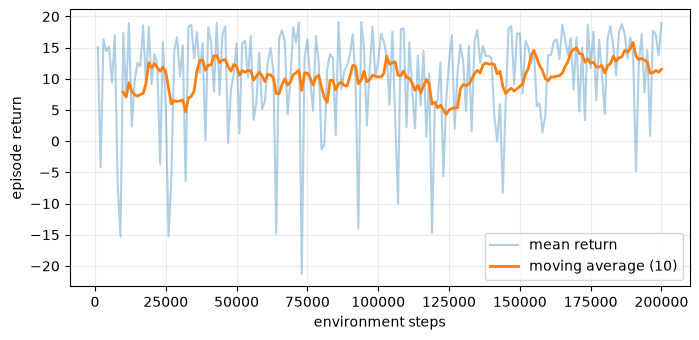

In [9]:
if RESULTS["training"]["curve"]:
    plot_learning_curve(RESULTS["training"]["curve"])
else:
    print("No training run recorded yet.")

**5.3 Learning curves, all seeds.** Thin lines are single runs, the bold line is the average over seeds. Look at how far apart the seeds are and whether any line trends up.

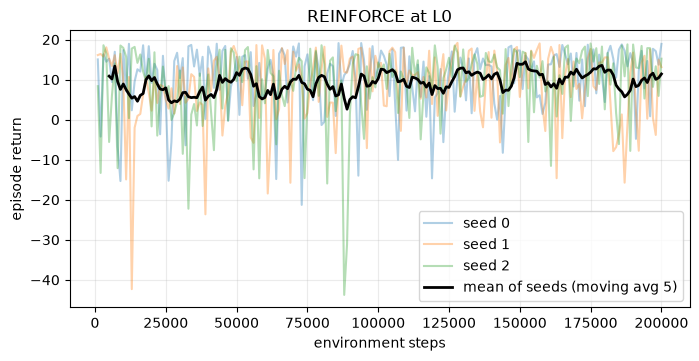

In [10]:
def plot_seeds(level, window=5):
    runs = [r for r in RESULTS["training"]["runs"].values() if r["level"] == level]
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for r in runs:
        ax.plot([p["timesteps"] for p in r["curve"]], [p["mean_return"] for p in r["curve"]], alpha=0.35,
                label=f"seed {r['train_seed']}")
    n = min(len(r["curve"]) for r in runs)
    mean = np.mean([[p["mean_return"] for p in r["curve"][:n]] for r in runs], axis=0)
    xs = np.mean([[p["timesteps"] for p in r["curve"][:n]] for r in runs], axis=0)
    ax.plot(xs[window - 1:], np.convolve(mean, np.ones(window) / window, mode="valid"), "k", linewidth=2,
            label=f"mean of seeds (moving avg {window})")
    ax.set_title(f"REINFORCE at L{level}"); ax.set_xlabel("environment steps"); ax.set_ylabel("episode return")
    ax.legend(); ax.grid(alpha=0.25); plt.show()

plot_seeds(level=0)

**5.4 What I tried when L0 did not improve** (following the debugging order: returns and log-probs, learning rate, normalisation, batching). These were side experiments on training seed 0 only (200,000 steps each, scripts outside the notebook). To judge them I used the training curve and the mean-action policy on 10 *tuning* seeds (2000 to 2009), never the held-out seeds 1000 to 1019. The reference is the zero-action policy on the same tuning seeds: reward 15.5, altitude error 3.8 cm.

| Change | Result |
|---|---|
| Returns | `compute_returns` reproduces the worked example of Section 3.4 (2.62, 1.8, 2.0). Correct. |
| Exploration noise sigma = 0.37 (log-std -1) | Training return about -500. Climb and lateral commands are *velocities*, so noise on them adds up to drift: the drone ended about 1 m off altitude. Lowering sigma to 0.1 fixed it. |
| Learning rate 3e-3 or 1e-2, returns normalised | Unstable, returns fell to -50 or even -1500. |
| Return normalisation on (lr 1e-4, 3e-4) | Flat or getting worse. At L0 almost every step has a similar return, so dividing by the standard deviation blows tiny differences up into full-size random updates. Turned off. |
| 4 episodes per update, lr 3e-4 | Curve flat, held-out result equal to zero action. |
| **1 episode per update, lr 3e-4, no normalisation** | Best: tuning-seed reward 16.6 and altitude error 3.2 cm, against 15.5 and 3.8 cm for zero action. Small gain, on only 10 episodes, so treat it as suggestive, not proven. |

**5.5 Level 1.** Same code, same hyperparameters, now with a 0.15 m spawn offset and the progress reward on. The drone has to fly the 8 m row.

In [11]:
run_seeds(level=1)

seed 0 L1 step   10000 return  -12.81 sigma 0.10


seed 0 L1 step   20000 return    4.28 sigma 0.10


seed 0 L1 step   30000 return  -25.38 sigma 0.10


seed 0 L1 step   40000 return   19.49 sigma 0.10


seed 0 L1 step   50000 return   12.80 sigma 0.10


seed 0 L1 step   60000 return   -2.66 sigma 0.10


... (51 outputs left out)

seed 2 L1 step  170000 return   24.54 sigma 0.10


seed 2 L1 step  180000 return  -63.48 sigma 0.10


seed 2 L1 step  190000 return   23.38 sigma 0.10


seed 2 L1 step  200000 return  -17.24 sigma 0.10
L1 seed 2: 200000 steps in 73 s (365 s per 1M steps), best training avg return 24.01


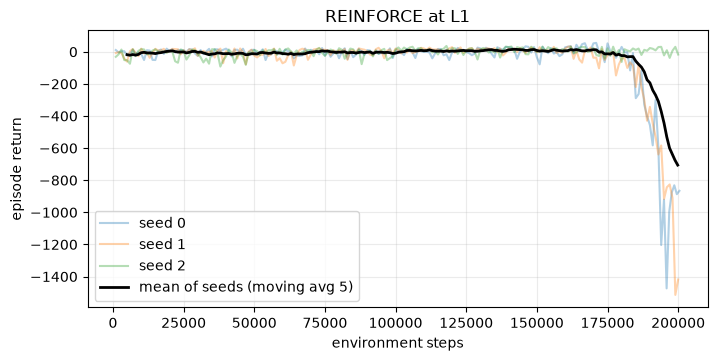

In [12]:
plot_seeds(level=1)

<a id="evaluation"></a>

## 6. Evaluation

Every policy is evaluated on the same held-out seeds (1000 to 1019) with exploration disabled. The two hand-coded baselines run at this notebook's level (`EXPERIMENT["level"]`, L0 by default); re-run them if the environment changes.

In [13]:
from agroflight.evaluation.evaluate_policy import evaluate
from agroflight.baselines import altitude_hold_action, random_action

eval_env = gym.make(ENV_ID, level=EXPERIMENT["level"])
rng = np.random.default_rng(0)

RESULTS["evaluation"]["baselines"]["altitude_hold"] = evaluate(
    altitude_hold_action, seeds=EXPERIMENT["eval_seeds"], env=eval_env)
RESULTS["evaluation"]["baselines"]["random"] = evaluate(
    lambda obs: random_action(eval_env.action_space, rng), seeds=EXPERIMENT["eval_seeds"], env=eval_env)

for name, st in RESULTS["evaluation"]["baselines"].items():
    print(f"{name:<14} reward {st['mean_reward']:8.1f}  crash {st['crash_rate']:.0%}  finish {st['finish_rate']:.0%}")

altitude_hold  reward     19.8  crash 0%  finish 0%
random         reward      6.5  crash 0%  finish 0%


**6.1 Evaluate the trained policies.** `make_trained_policy` rebuilds the network, loads the saved best weights and returns a function `obs -> action` that uses the **mean** action (no noise), as the shared `evaluate` helper expects. Every training run is then evaluated on the 20 held-out seeds (1000 to 1019) at its own level. I also add a **zero-action** baseline (the drone is told "do nothing, hold position"), because it shows how much of a level is solved by the inner controller alone.

In [14]:
def make_trained_policy(tag):
    model = GaussianPolicy(14, 4)
    load_checkpoint(model, tag=tag)
    model.eval()
    def trained_policy(obs):
        with torch.no_grad():
            return model(torch.as_tensor(obs, dtype=torch.float32)).mean.numpy()   # deterministic: no noise
    return trained_policy

RESULTS["evaluation"].setdefault("per_seed", {})

def evaluate_level(level):
    """Evaluate every training run of this level, plus the zero-action and altitude-hold baselines."""
    env_l = gym.make(ENV_ID, level=level)
    seeds = EXPERIMENT["eval_seeds"]
    for name, run in RESULTS["training"]["runs"].items():
        if run["level"] != level:
            continue
        tag = "best" if name == "L0_seed0" else name
        stats = evaluate(make_trained_policy(tag), seeds=seeds, env=env_l)
        RESULTS["evaluation"]["per_seed"][name] = stats
        if run["train_seed"] == 0:
            RESULTS["evaluation"]["levels"][f"L{level}"] = stats   # main entry of the shared schema
        print(f"{name}: reward {stats['mean_reward']:8.1f}  crash {stats['crash_rate']:.0%}  finish {stats['finish_rate']:.0%}  "
              f"|alt err| {stats['mean_abs_alt_error']:.3f} m")
    RESULTS["evaluation"]["baselines"][f"zero_action@L{level}"] = evaluate(
        lambda obs: np.zeros(4, dtype=np.float32), seeds=seeds, env=env_l)
    if level > 0:
        RESULTS["evaluation"]["baselines"][f"altitude_hold@L{level}"] = evaluate(altitude_hold_action, seeds=seeds, env=env_l)
    env_l.close()

evaluate_level(0)
print("zero action @L0:", {k: round(v, 3) for k, v in RESULTS["evaluation"]["baselines"]["zero_action@L0"].items()})

L0_seed0: reward     15.6  crash 0%  finish 0%  |alt err| 0.038 m


L0_seed1: reward     11.5  crash 0%  finish 0%  |alt err| 0.049 m


L0_seed2: reward     14.4  crash 0%  finish 0%  |alt err| 0.041 m


zero action @L0: {'mean_reward': 14.862, 'std_reward': 5.623, 'crash_rate': 0.0, 'finish_rate': 0.0, 'mean_steps': 1000.0, 'mean_abs_alt_error': 0.042, 'n_episodes': 20}


**6.2 Level 1 evaluation.** Same protocol at L1, with the altitude-hold baseline evaluated at L1 too.

In [15]:
evaluate_level(1)
print("altitude_hold @L1:", {k: round(v, 3) for k, v in RESULTS["evaluation"]["baselines"]["altitude_hold@L1"].items()})

L1_seed0: reward     11.2  crash 0%  finish 0%  |alt err| 0.054 m


L1_seed1: reward     10.4  crash 0%  finish 0%  |alt err| 0.042 m


L1_seed2: reward      8.2  crash 0%  finish 0%  |alt err| 0.042 m


altitude_hold @L1: {'mean_reward': 3.914, 'std_reward': 13.64, 'crash_rate': 0.0, 'finish_rate': 0.0, 'mean_steps': 1000.0, 'mean_abs_alt_error': 0.003, 'n_episodes': 20}


<a id="results"></a>

## 7. Results

In [16]:
import pandas as pd

def cleared(st, level):
    """DRAFT success criterion (Section 1, not yet agreed with the team)."""
    ok = st["crash_rate"] <= 0.10
    if level == 0:
        return ok and st["mean_abs_alt_error"] <= 0.05
    return ok and st["finish_rate"] >= 0.80

rows = []
for name, st in RESULTS["evaluation"]["baselines"].items():
    level = int(name.split("@L")[1]) if "@L" in name else EXPERIMENT["level"]
    rows.append({"policy": name, "cleared": cleared(st, level), **st})
for key, st in RESULTS["evaluation"]["per_seed"].items():
    rows.append({"policy": f"REINFORCE {key}", "cleared": cleared(st, int(key[1])), **st})

cols = ["mean_reward", "std_reward", "crash_rate", "finish_rate", "mean_steps", "mean_abs_alt_error", "cleared"]
df = pd.DataFrame(rows).set_index("policy")[cols]
display(df.round(3))
for level in sorted({int(k[1]) for k in RESULTS["evaluation"]["per_seed"]}):
    ks = [k for k in RESULTS["evaluation"]["per_seed"] if int(k[1]) == level]
    n_ok = sum(cleared(RESULTS["evaluation"]["per_seed"][k], level) for k in ks)
    print(f"L{level}: cleared by {n_ok} of {len(ks)} training seeds")

,mean_reward,std_reward,crash_rate,finish_rate,mean_steps,mean_abs_alt_error,cleared
policy,,,,,,,
altitude_hold,19.781,0.240,0.0,0.0,1000.0,0.003,True
random,6.485,8.028,0.0,0.0,1000.0,0.056,False
zero_action@L0,14.862,5.623,0.0,0.0,1000.0,0.042,True
zero_action@L1,-1.005,16.339,0.0,0.0,1000.0,0.042,False
altitude_hold@L1,3.914,13.640,0.0,0.0,1000.0,0.003,False
REINFORCE L0_seed0,15.558,5.271,0.0,0.0,1000.0,0.038,True
REINFORCE L0_seed1,11.483,9.177,0.0,0.0,1000.0,0.049,True
REINFORCE L0_seed2,14.434,6.476,0.0,0.0,1000.0,0.041,True
REINFORCE L1_seed0,11.151,31.928,0.0,0.0,1000.0,0.054,False


L0: cleared by 3 of 3 training seeds
L1: cleared by 0 of 3 training seeds


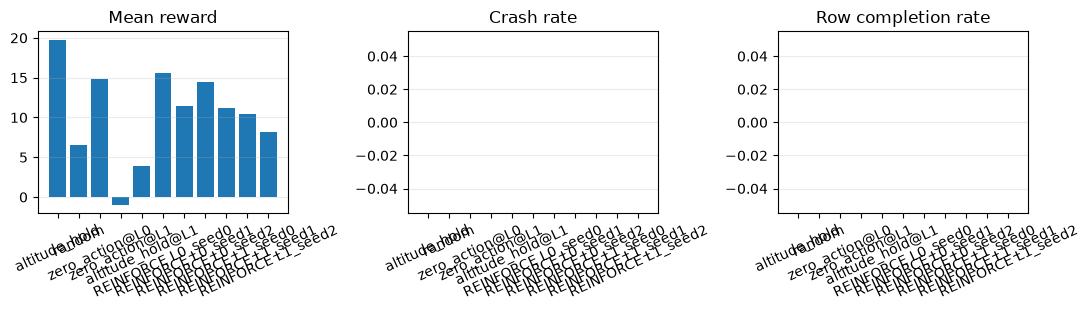

results saved to /Users/juandavid/Desktop/semester_4/reinforcement_learning/Project/agroflight-rl-main/results/reinforce_25418551.json


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, title in zip(axes, ["mean_reward", "crash_rate", "finish_rate"],
                          ["Mean reward", "Crash rate", "Row completion rate"]):
    ax.bar(df.index, df[col])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

path = save_results(RESULTS)
print("results saved to", path)
if BACKUP_TO_DRIVE:
    backup_to_drive([RESULTS_DIR, CHECKPOINT_DIR])

**Headline (200,000 steps per run, 3 seeds, 20 held-out seeds, draft criterion from Section 1).** REINFORCE **clears L0 in 3 of 3 seeds and clears L1 in 0 of 3**, so the highest level cleared is L0. Two things stop me from calling the L0 result a success:

- **L0 is not discriminating.** The do-nothing baseline (all-zero action) also clears L0: 0% crashes, 4.2 cm altitude error, reward 14.9. REINFORCE gets reward 15.6 / 11.5 / 14.4 (mean 13.8) and 3.8 / 4.9 / 4.1 cm. Only the hand-coded altitude-hold baseline is clearly better (reward 19.8, 0.3 cm). So there is **no evidence that REINFORCE learned anything at L0** beyond what the inner controller already does. Seed 1 is even slightly worse than doing nothing, and at 4.9 cm it only just passes the 5 cm limit.
- **At L1 REINFORCE learned to move, but not to finish.** Reward is 11.2 / 10.4 / 8.2, better than both baselines at L1 (zero action -1.0, altitude-hold 3.9), because the progress reward pays for forward motion. But 0% of the 20 episodes finished the row for every seed (0% crashes). On 5 extra seeds (2000 to 2004, not held-out) the seed-0 policy reached x = 5.0 m of 8 m, seed 2 reached 1.5 m and seed 1 only 0.9 m.

**Against my success criterion** (L0 with 3 of 3 seeds, L1 with at least 2 of 3): the L0 part is met (with the caveat above), the L1 part is not. Failing at L1 is an acceptable and reportable result. **The criterion is still a draft the team has not agreed.** The hyperparameters were chosen on seed 0 at L0 with training returns and 10 tuning seeds (Section 5.4), then reused at L1 without tuning, so L1 is probably not REINFORCE's best case.

<a id="discussion"></a>

## 8. Discussion

**Was training stable across seeds?** No. Average training return over the first 20 and last 20 updates (200 updates per run):

| Run | first 20 | last 20 | worst single update |
|---|---|---|---|
| L0 seed 0 | 9.8 | 13.7 | -21 |
| L0 seed 1 | 6.4 | 4.1 | -42 |
| L0 seed 2 | 9.3 | 11.1 | -44 |
| L1 seed 0 | -7.1 | **-576** | -1474 |
| L1 seed 1 | -6.1 | **-526** | -1514 |
| L1 seed 2 | -9.7 | 7.9 | -92 |

At L0 the seeds drift up or down by a few points, which is about the size of the noise in a single episode. At L1, seeds 0 and 1 collapsed late in training (returns around -1500 mean the drone flew far from the target altitude for a whole episode), while seed 2 stayed calm but barely moved. The saved "best" checkpoint is chosen by training return before the collapse, which is why the evaluated L1 policies are still reasonable. The variance Part B predicted is clearly visible.

**Did the reward behave as intended?** I have **not** looked at the viewer, so I cannot say whether the flights look sensible or whether the reward is being exploited. What the numbers do show: at L1 the forward-motion reward pulls the policy forward (mean forward action 0.26 in seed 0), and the collapsed runs are consistent with the drone drifting away from the altitude target. **To do before submitting: watch the L0 and L1 checkpoints in the viewer.**

**Where did it fail: algorithm, reward or environment?** My reading, not proven by an experiment:
- *Algorithm.* Vanilla REINFORCE has no baseline, so an update is driven by the whole episode's return. At L0 most of the return difference between episodes comes from the random start altitude (up to 10 cm), which the policy does not control, and this buries the small effect of its own actions. Return normalisation made it worse, and larger learning rates were unstable (Section 5.4).
- *Environment.* At L0 the zero action already passes the 5 cm criterion, so L0 cannot show learning. Climb and lateral commands are velocities, so exploration noise accumulates as drift and forces a small $\sigma$. I did not change the environment; these are points to raise with the team.
- *Not tested:* the reward weights (Reward v1 is untuned) and any effect of the 200,000-step budget on L1.

**Limits.** MuJoCo has no rotor ground effect or canopy turbulence; the wind is part of the observation; one environment; 3 seeds and 20 evaluation episodes are small samples; hyperparameters were tuned on seed 0 at L0 only; L2 to L4 were not run.

**What I would try next** (ideas, not tested): a learned baseline or critic (this is what A2C adds), a much smaller or annealed $\sigma$, normalising the observation, gradient clipping, choosing the best checkpoint with a rolling evaluation on tuning seeds, more seeds, and longer runs.

<a id="contribution"></a>

## 9. Contribution and reproducibility

<div style="border-left:4px solid rgb(147,105,28);background:rgba(147,105,28,0.10);padding:10px 14px;border-radius:0 8px 8px 0;margin:6px 0"><b>Write here.</b> Contribution statement (marks are split by individual contribution). Fill in the table.</div>

| | |
|---|---|
| **My contribution** | *what Juan built, ran and wrote* |
| **Shared work with teammates** | *environment rework, evaluation harness, viewer, report sections* |
| **AI assistance used** | Claude (Anthropic) explained RL concepts, scaffolded the notebook and the environment, and drafted the plain-language text in Sections 1, 3 and 5. In the REINFORCE session it also wrote the code of Sections 4 to 6 (Gaussian policy, returns, update, training loop, evaluation cells), ran the L0 and L1 experiments and the debugging side-experiments of Section 5.4, and drafted Sections 5 (setup actually run), 7 and 8 from the numbers it produced. **What I must still verify myself:** that I can explain every line of Section 4 and the training loop; that the numbers in Sections 5 to 8 match a fresh run of the notebook; the viewer check of the flights (not done by the assistant); and that I rewrote the drafted text in my own words. **[Juan: edit this sentence to say what you actually checked.]** |

In [18]:
import platform
print("python    :", platform.python_version())
print("torch     :", torch.__version__)
print("numpy     :", np.__version__)
print("gymnasium :", gym.__version__)
print("mujoco    :", mujoco.__version__)
print("git commit:", git_commit())
print("train seed:", EXPERIMENT["train_seed"], "| eval seeds:", EXPERIMENT["eval_seeds"][0], "to", EXPERIMENT["eval_seeds"][-1])
print("notebook wall-clock so far: %.0f s" % (time.time() - NOTEBOOK_T0))

python    : 3.11.4
torch     : 2.14.0
numpy     : 2.4.6
gymnasium : 1.3.0
mujoco    : 3.12.0
git commit: 56156ca
train seed: 0 | eval seeds: 1000 to 1019
notebook wall-clock so far: 7949 s


### References

1. Williams, R. J. (1992). Simple statistical gradient-following algorithms for connectionist reinforcement learning. Machine Learning 8, 229-256.
2. Sutton, R. S., McAllester, D., Singh, S., Mansour, Y. (2000). Policy gradient methods for reinforcement learning with function approximation. NeurIPS.
3. Todorov, E., Erez, T., Tassa, Y. (2012). MuJoCo: A physics engine for model-based control. IROS.
4. Google DeepMind. MuJoCo Menagerie: Skydio X2 model (Apache-2.0). github.com/google-deepmind/mujoco_menagerie.
5. Towers, M. et al. (2024). Gymnasium: A Standard Interface for Reinforcement Learning Environments. arXiv:2407.17032.